# Observed shapes: diffusion, ResNet and ResNet-D5

Local comparison using the frozen Figure 6 v03 prediction cache. Apply the existing
fixed Gaussian-weighted moments and independent GalSim adaptive moments to signed
physical images. No source-segmentation clipping: that would impose the reference
outline on the reconstructed shapes. All methods use the same valid pixels.
Within each estimator, every error comparison uses the intersection of successful
reference and six reconstruction/baseline measurements. Full-denominator success
fractions accompany the errors; an additional table fixes the intersection across
both estimators. These are observed ellipticities, not PSF-corrected shear.

All choices were saved before evaluating the images. No inference or upload.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from IPython.display import display
here=Path.cwd();workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:sys.path.insert(0,str(workspace))
from figure_utils import ROOT,FIGURES,COLORS,style,read_json,sha,export
%matplotlib inline
style()
VERSION='v01'
path=FIGURES/'inputs'/f'cached_shapes_{VERSION}.json'
b=read_json(path)
assert b['complete'] and b['local_only']
assert sha(ROOT/b['arrays_path'])==b['arrays_sha256']
with np.load(ROOT/b['arrays_path']) as f:arrays={k:f[k] for k in f.files}
names=b['methods'];labels={'bilinear':'Bilinear','bicubic':'Bicubic','diffusion':'Diffusion (1 sample)',
'diffusion_mean3':'Diffusion (mean of 3)','legacy':'ResNet','direct5':'ResNet-D5'}
colors={**COLORS,'diffusion_mean3':'#B485B8'}
print('Attempted:',len(b['object_ids']),'Common across both estimators:',b['cross_estimator_objects'])


Attempted: 2118 Common across both estimators: 1313


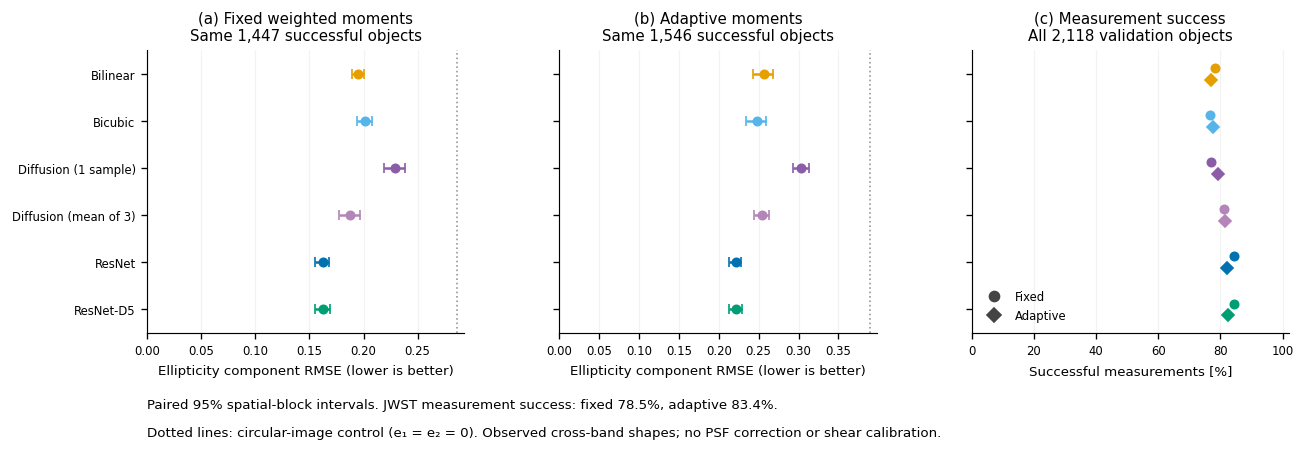

Exported: fig07_model_shapes_v01.pdf, fig07_model_shapes_v01.svg, fig07_model_shapes_v01.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v01.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v01.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v01.png')]

In [2]:
fig,axes=plt.subplots(1,3,figsize=(11.6,4.2),sharey=True)
y=np.arange(len(names))
for ax,case,title in zip(axes[:2],['fixed','adaptive'],['(a) Fixed weighted moments','(b) Adaptive moments']):
    summary=b['summaries'][case]
    for i,name in enumerate(names):
        rec=summary['methods'][name]['component_rmse'];value=rec['mean'];lo,hi=rec['ci95']
        ax.errorbar(value,i,xerr=np.array([[value-lo],[hi-value]]),fmt='o',color=colors[name],capsize=3,ms=5)
    control=summary['methods']['round_control']['component_rmse']['mean']
    ax.axvline(control,color='#999999',ls=':',lw=1)
    ax.set_xlim(left=0)
    ax.set_xlabel('Ellipticity component RMSE (lower is better)')
    ax.set_title(f"{title}\nSame {summary['common_successes']:,} successful objects")
axes[0].set_yticks(y,[labels[m] for m in names])
for case,marker,offset in [('fixed','o',-.12),('adaptive','D',.12)]:
    for i,name in enumerate(names):
        fraction=100*b['summaries'][case]['success_counts'][name]/len(b['object_ids'])
        axes[2].plot(fraction,i+offset,marker,color=colors[name],ms=5)
axes[2].set_title('(c) Measurement success\nAll 2,118 validation objects')
axes[2].set_xlim(0,102);axes[2].set_xlabel('Successful measurements [%]')
axes[2].legend(handles=[Line2D([],[],color='#444444',marker='o',ls='',label='Fixed'),Line2D([],[],color='#444444',marker='D',ls='',label='Adaptive')],loc='lower left',frameon=False)
for ax in axes:
    ax.set_ylim(len(names)-.5,-.5);ax.grid(axis='x',alpha=.15)
fig.subplots_adjust(left=.17,right=.99,top=.81,bottom=.25,wspace=.3)
fixed_ref=100*b['summaries']['fixed']['success_counts']['target']/len(b['object_ids'])
adaptive_ref=100*b['summaries']['adaptive']['success_counts']['target']/len(b['object_ids'])
fig.text(.17,.10,f'Paired 95% spatial-block intervals. JWST measurement success: fixed {fixed_ref:.1f}%, adaptive {adaptive_ref:.1f}%.',fontsize=8)
fig.text(.17,.045,'Dotted lines: circular-image control (e₁ = e₂ = 0). Observed cross-band shapes; no PSF correction or shear calibration.',fontsize=8)
plt.show()
export(fig,f'fig07_model_shapes_{VERSION}','07b_model_shapes.ipynb',[path],
       dict(population=b['population'],fixed=b['fixed'],adaptive=b['adaptive'],summary=b['summary']),
       status='Local matched observed-shape comparison and full-denominator measurement success')


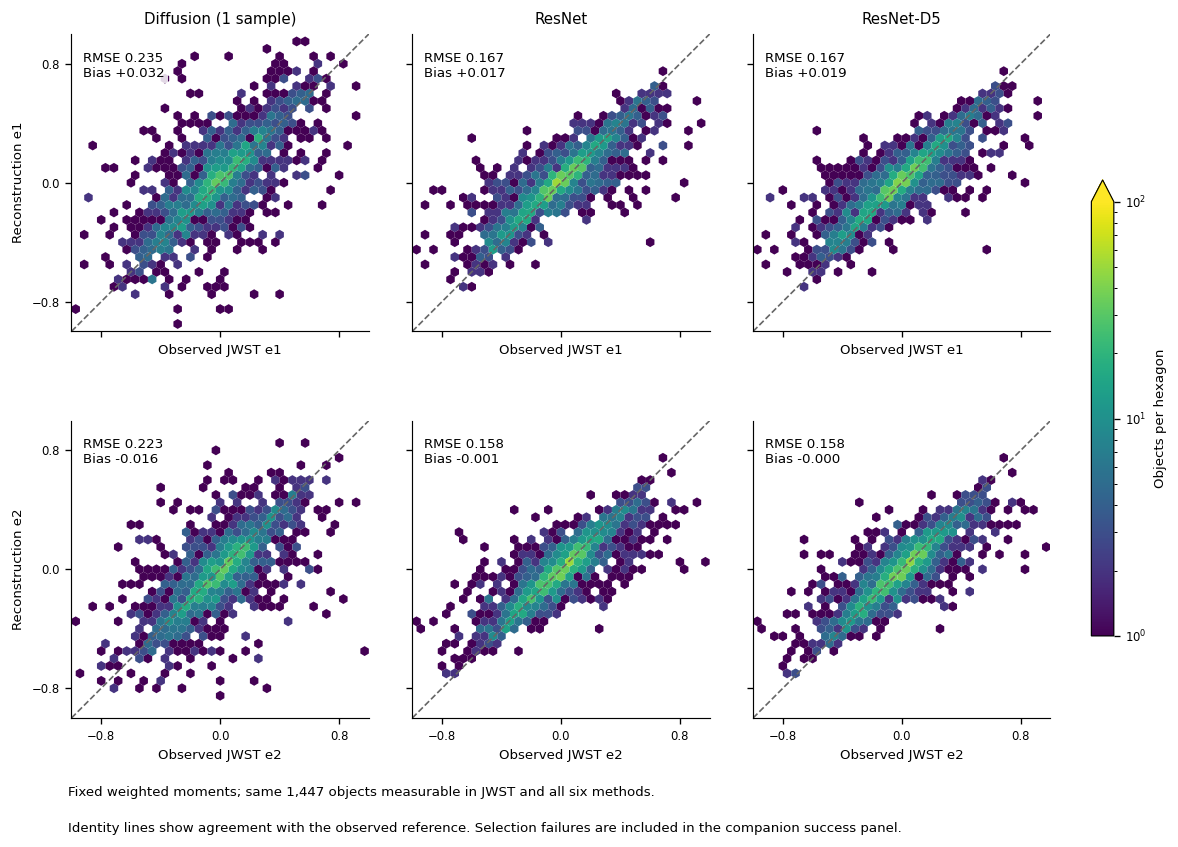

Exported: fig07_model_shape_agreement_v01.pdf, fig07_model_shape_agreement_v01.svg, fig07_model_shape_agreement_v01.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shape_agreement_v01.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shape_agreement_v01.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shape_agreement_v01.png')]

In [3]:
# Shape agreement for the three requested learned models, on identical objects.
case='fixed';summary=b['summaries'][case]
keep=np.isin(arrays['object_ids'],summary['object_ids'])
ref=arrays[f'{case}__target__e'][keep]
fig,axes=plt.subplots(2,3,figsize=(10.4,7.6),sharex=True,sharey=True)
for j,name in enumerate(['diffusion','legacy','direct5']):
    pred=arrays[f'{case}__{name}__e'][keep]
    for k in range(2):
        ax=axes[k,j]
        artist=ax.hexbin(ref[:,k],pred[:,k],gridsize=35,extent=(-1,1,-1,1),mincnt=1,
                         norm=LogNorm(vmin=1,vmax=100),cmap='viridis',linewidths=0)
        ax.plot([-1,1],[-1,1],color='#666666',ls='--',lw=1)
        ax.set_xlim(-1,1);ax.set_ylim(-1,1);ax.set_aspect('equal')
        ax.set_xticks([-.8,0,.8]);ax.set_yticks([-.8,0,.8])
        delta=pred[:,k]-ref[:,k]
        ax.text(.04,.94,f'RMSE {np.sqrt(np.mean(delta**2)):.3f}\nBias {np.mean(delta):+.3f}',
                transform=ax.transAxes,va='top',fontsize=8,bbox=dict(facecolor='white',edgecolor='none',alpha=.85,pad=2))
        if k==0:ax.set_title(labels[name])
        if j==0:ax.set_ylabel(f'Reconstruction e{k+1}')
        ax.set_xlabel(f'Observed JWST e{k+1}')
fig.subplots_adjust(left=.09,right=.88,top=.91,bottom=.16,wspace=.12,hspace=.30)
cax=fig.add_axes([.91,.25,.018,.5]);fig.colorbar(artist,cax=cax,label='Objects per hexagon',extend='max')
fig.text(.09,.075,f"Fixed weighted moments; same {summary['common_successes']:,} objects measurable in JWST and all six methods.",fontsize=8)
fig.text(.09,.035,'Identity lines show agreement with the observed reference. Selection failures are included in the companion success panel.',fontsize=8)
plt.show()
export(fig,f'fig07_model_shape_agreement_{VERSION}','07b_model_shapes.ipynb',[path],
       dict(estimator=case,objects=int(keep.sum()),methods=['diffusion','legacy','direct5']),
       status='Local observed ellipticity component agreement on a matched success population')


In [4]:
rows=[]
for population,summaries in [('Per-estimator common',b['summaries']),('Both estimators common',b['cross_estimator_common'])]:
    for estimator,summary in summaries.items():
        for name in names:
            rec=summary['methods'][name]
            rows.append(dict(population=population,estimator=estimator,objects=summary['common_successes'],method=labels[name],
                component_rmse=rec['component_rmse']['mean'],ci95=rec['component_rmse']['ci95'],bias_e1=rec['bias']['mean'][0],bias_e2=rec['bias']['mean'][1],
                large_error_fraction=rec['vector_error_above_0_2_fraction']['mean']))
display(pd.DataFrame(rows))


,population,estimator,objects,method,component_rmse,ci95,bias_e1,bias_e2,large_error_fraction
0,Per-estimator common,fixed,1447,Bilinear,0.195185,"[0.18915280981879565, 0.20041235438613103]",0.010763,0.000590,0.399447
1,Per-estimator common,fixed,1447,Bicubic,0.201521,"[0.19427855040500475, 0.2079616287480699]",0.010499,-0.000252,0.375259
2,Per-estimator common,fixed,1447,Diffusion (1 sample),0.229191,"[0.2187491032186675, 0.23797891184357822]",0.032308,-0.016106,0.429855
3,Per-estimator common,fixed,1447,Diffusion (mean of 3),0.187642,"[0.17754592463835342, 0.1962774249910492]",0.032018,-0.015299,0.352453
4,Per-estimator common,fixed,1447,ResNet,0.162439,"[0.1553829639717444, 0.16840072233322986]",0.017473,-0.001150,0.286800
5,Per-estimator common,fixed,1447,ResNet-D5,0.162584,"[0.15545803794071936, 0.16869723151992078]",0.019449,-0.000256,0.286800
6,Per-estimator common,adaptive,1546,Bilinear,0.256518,"[0.24339052125792648, 0.26833336565884086]",0.015318,-0.003600,0.606080
7,Per-estimator common,adaptive,1546,Bicubic,0.247705,"[0.2346942071279834, 0.2597248470480691]",0.014002,-0.005981,0.567917
8,Per-estimator common,adaptive,1546,Diffusion (1 sample),0.303118,"[0.29280209167424087, 0.3127769328906919]",0.037037,-0.016179,0.614489
9,Per-estimator common,adaptive,1546,Diffusion (mean of 3),0.253835,"[0.24363322079268057, 0.26344344020667254]",0.039396,-0.023459,0.531695


## Interpretation limits

The error bars condition on each estimator's matched successful sample. Report
full-population success fractions with the shape errors, and inspect the stricter
intersection across both estimators. Fixed and adaptive shapes use different
weights, so their absolute RMSE values have different targets. Galaxies in a
blend may contaminate both measurements; the adaptive centroid guard is not a
deblender. Mean-of-three refers to a mean image, not averaged ellipticity draws.
This cache cannot establish diffusion realization-to-realization shape scatter.
